# Board Games Data Mining
## 1. Data Understanding and Preparation

## Setup and Data Loading

In [1]:
from pathlib import Path
from itertools import combinations
import re
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path.cwd() / "DM1_game_dataset.csv"

print("Current working directory:", Path.cwd())
print("Dataset path:", DATA_PATH)

df = pd.read_csv(DATA_PATH)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Current working directory: /Users/sarabiiavasco/Codice/DATA MINING/PROGETTO DM1
Dataset path: /Users/sarabiiavasco/Codice/DATA MINING/PROGETTO DM1/DM1_game_dataset.csv
Loaded 21,925 rows and 46 columns


,BGGId,Name,Description,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,GoodPlayers,NumOwned,NumWant,NumWish,NumWeightVotes,MfgPlaytime,ComMinPlaytime,ComMaxPlaytime,MfgAgeRec,NumUserRatings,NumComments,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,Family,Kickstarted,ImagePath,Rank:strategygames,Rank:abstracts,Rank:familygames,Rank:thematic,Rank:cgs,Rank:wargames,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
0,140386,Assassin's Creed: Arena,game description publisherin assassins creed a...,2014,1.8333,2.0512,2,4,8.0,213.0,0,[],528,6,64,6,30,30,30,15,164,0,0,1,0,0,NaN,0,https://cf.geekdo-images.com/KODsRK0MYHHOMjcwp...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Low
1,344114,Bag of Chips,bag chip party game face crucial choice score ...,2021,1.0000,1.2256,2,5,8.0,36.0,0,[],72,12,47,6,20,15,20,8,38,0,1,0,0,0,NaN,0,https://cf.geekdo-images.com/qVKpawhjdPtv3mvcE...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Medium
2,319196,Gùgōng: Deluxe Big Box,big box contain component gugravegng deluxe ed...,2020,3.6667,3.8190,1,5,NaN,NaN,0,[],834,37,63,9,150,30,150,12,231,0,0,1,0,0,NaN,0,https://cf.geekdo-images.com/ip7NI05tygaMvaV1a...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,High
3,11404,LetterFlip,publisherthe reveal game secret wordsletterfli...,2004,1.3077,1.4216,2,2,7.0,NaN,0,[],154,2,7,13,20,20,20,10,81,0,0,0,0,0,NaN,0,https://cf.geekdo-images.com/K5ga4Gs_XAExVXP6z...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Low
4,281020,Treasures of Cibola,rescue mayan treasure easy task ...,2019,1.5000,1.6230,2,4,NaN,7.0,0,[],208,4,35,2,20,15,20,8,79,0,3,0,0,0,NaN,0,https://cf.geekdo-images.com/d5DWiG0N2augdAOYX...,21926,21926,21926,21926,21926,21926,21926,21926,0,0,0,0,0,0,0,0,Medium


### 1.1 Data Semantics

The dataset contains **21,925 games described by 46 original attributes**. Following the final report, the attributes are interpreted as:

- **Nominal:** `BGGId`, `Name`, `Description`, `ImagePath`, `Family`.
- **Ordinal:** `GameWeight`, `ComWeight`, `Rating`, `LanguageEase`, `Rank:*`.
- **Asymmetric binary:** `IsReimplementation`, `Kickstarted`, `Cat:*`.
- **Numerical:** the remaining count, age, year and play-time variables.

`BGGId` is stored numerically but is treated as an identifier rather than a quantitative variable.

In [2]:
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Shape: (21925, 46)
Columns:
['BGGId', 'Name', 'Description', 'YearPublished', 'GameWeight', 'ComWeight', 'MinPlayers', 'MaxPlayers', 'ComAgeRec', 'LanguageEase', 'BestPlayers', 'GoodPlayers', 'NumOwned', 'NumWant', 'NumWish', 'NumWeightVotes', 'MfgPlaytime', 'ComMinPlaytime', 'ComMaxPlaytime', 'MfgAgeRec', 'NumUserRatings', 'NumComments', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'IsReimplementation', 'Family', 'Kickstarted', 'ImagePath', 'Rank:strategygames', 'Rank:abstracts', 'Rank:familygames', 'Rank:thematic', 'Rank:cgs', 'Rank:wargames', 'Rank:partygames', 'Rank:childrensgames', 'Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 'Cat:Childrens', 'Rating']


### 1.2 DType Analysis

In [3]:
print("Initial memory usage and dtypes:")
df.info(memory_usage="deep")

Initial memory usage and dtypes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21925 entries, 0 to 21924
Data columns (total 46 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   BGGId                21925 non-null  int64  
 1   Name                 21925 non-null  object 
 2   Description          21924 non-null  object 
 3   YearPublished        21925 non-null  int64  
 4   GameWeight           21925 non-null  float64
 5   ComWeight            21925 non-null  float64
 6   MinPlayers           21925 non-null  int64  
 7   MaxPlayers           21925 non-null  int64  
 8   ComAgeRec            16395 non-null  float64
 9   LanguageEase         16034 non-null  float64
 10  BestPlayers          21925 non-null  int64  
 11  GoodPlayers          21925 non-null  object 
 12  NumOwned             21925 non-null  int64  
 13  NumWant              21925 non-null  int64  
 14  NumWish              21925 non-null  int64  
 15  Num

In [4]:
def optimize_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """Downcast numeric columns and use pandas semantic dtypes where possible."""
    out = df.copy()

    for col in out.select_dtypes(include=[np.number]).columns:
        s = out[col]
        non_null = s.dropna()
        if non_null.empty:
            continue

        if non_null.isin([0, 1]).all():
            out[col] = s.astype("boolean")
            continue

        # Integer-valued numeric columns -> smallest nullable integer dtype.
        if pd.api.types.is_integer_dtype(s) or np.allclose(non_null, non_null.astype(int)):
            mn, mx = int(non_null.min()), int(non_null.max())
            if mn >= 0:
                dtype = "UInt8" if mx <= 255 else "UInt16" if mx <= 65535 else "UInt32" if mx <= 4294967295 else "UInt64"
            else:
                dtype = "Int8" if -128 <= mn and mx <= 127 else "Int16" if -32768 <= mn and mx <= 32767 else "Int32" if -2147483648 <= mn and mx <= 2147483647 else "Int64"
            out[col] = s.astype(dtype)
        else:
            out[col] = s.astype("Float32")

    for col in out.select_dtypes(include=["object"]).columns:
        s = out[col]
        if s.dropna().map(lambda x: isinstance(x, str)).all():
            s = s.astype("string").str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
            out[col] = s.astype("category") if s.nunique(dropna=True) <= 100 else s

    return out

memory_before = df.memory_usage(deep=True).sum() / 1024**2
df = optimize_dtypes(df)
memory_after = df.memory_usage(deep=True).sum() / 1024**2

print(f"Memory before: {memory_before:.2f} MB")
print(f"Memory after : {memory_after:.2f} MB")
print(f"Reduction    : {(memory_before-memory_after)/memory_before:.2%}")

Memory before: 30.22 MB
Memory after : 24.01 MB
Reduction    : 20.56%


### 1.3 Distribution and Statistics

In [5]:
# Descriptive statistics for numerical variables.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BGGId,21925.0,117652.663216,104628.721777,1.0,12346.0,105305.0,206169.0,349161.0
YearPublished,21925.0,1985.494914,212.486214,-3500.0,2001.0,2011.0,2017.0,2021.0
GameWeight,21925.0,1.982131,0.848983,0.0,1.3333,1.9688,2.5252,5.0
ComWeight,21925.0,2.177479,0.861781,0.0,1.5134,2.128,2.7377,5.2132
MinPlayers,21925.0,2.007343,0.693093,0.0,2.0,2.0,2.0,10.0
MaxPlayers,21925.0,5.707868,15.014643,0.0,4.0,4.0,6.0,999.0
ComAgeRec,16395.0,10.004377,3.269158,2.0,8.0,10.0,12.0,21.0
LanguageEase,16034.0,216.461655,236.595062,1.0,24.027779,138.0,351.0,1757.0
BestPlayers,21925.0,0.311517,1.067002,0.0,0.0,0.0,0.0,15.0
NumOwned,21925.0,1467.848164,5294.120574,0.0,150.0,320.0,899.0,166497.0


#### Duplicate records

In [6]:
# Fully duplicated records, ignoring the identifier.
cols_no_id = [c for c in df.columns if c != "BGGId"]
full_duplicates = df.duplicated(subset=cols_no_id, keep=False)
print("Fully duplicated rows excluding BGGId:", int(full_duplicates.sum()))

Fully duplicated rows excluding BGGId: 0


In [7]:
from itertools import combinations

def scan_partial_duplicates(frame, max_different_cols=3, ignore=("BGGId",)):
    cols = [c for c in frame.columns if c not in ignore]
    findings = []

    for n_diff in range(1, max_different_cols + 1):
        for omitted in combinations(cols, n_diff):

            subset = [c for c in cols if c not in omitted]

            mask = frame.duplicated(
                subset=subset,
                keep=False
            )

            if mask.any():
                findings.append({
                    "different_columns": omitted,
                    "matching_rows": int(mask.sum())
                })

    return pd.DataFrame(
        findings,
        columns=["different_columns", "matching_rows"]
    )


RUN_EXHAUSTIVE_PARTIAL_DUPLICATE_SCAN = True

if RUN_EXHAUSTIVE_PARTIAL_DUPLICATE_SCAN:

    partial_duplicate_summary = scan_partial_duplicates(df)

    if partial_duplicate_summary.empty:
        print(
            "No partial duplicates found when allowing "
            "differences in up to 3 columns."
        )
    else:
        display(
            partial_duplicate_summary
            .sort_values("matching_rows", ascending=False)
            .head(20)
        )

else:
    print(
        "Partial-duplicate scan defined but not executed "
        "(set flag to True to run)."
    )

No partial duplicates found when allowing differences in up to 3 columns.


#### Numerical distributions

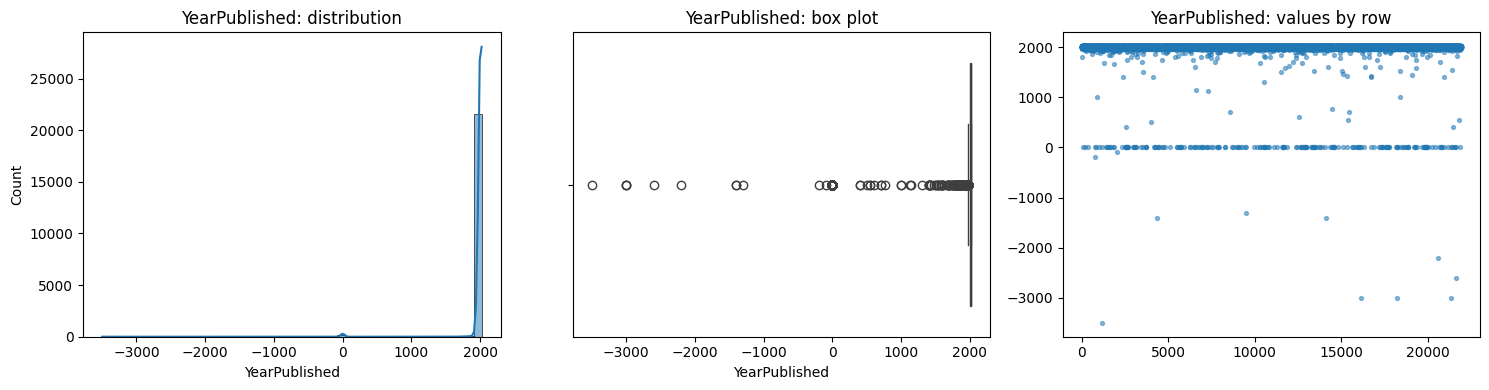

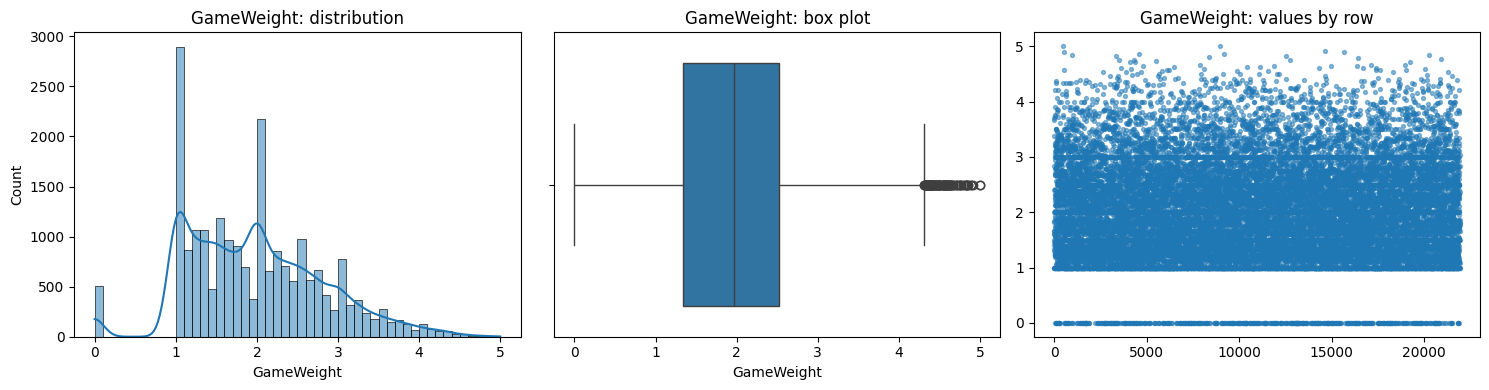

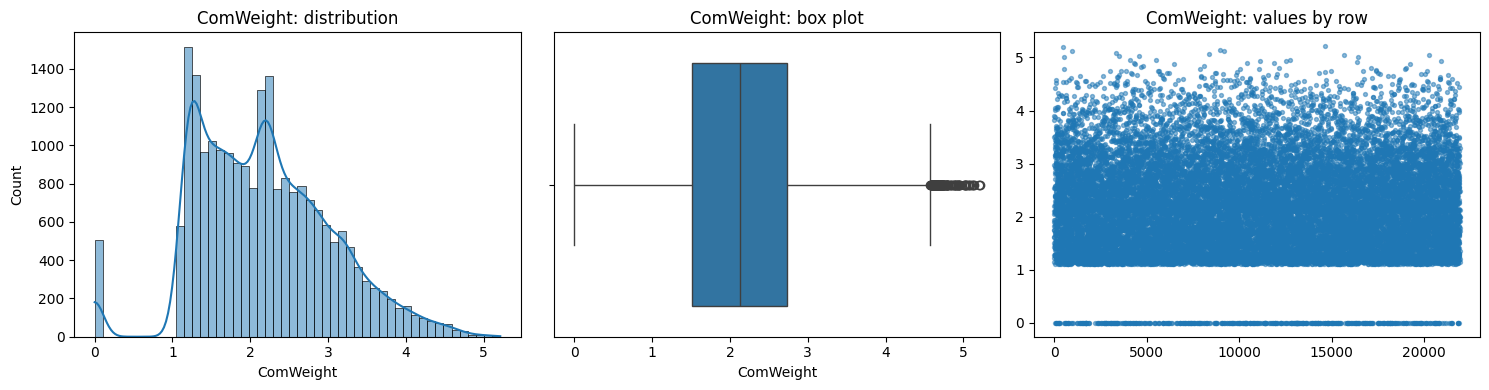

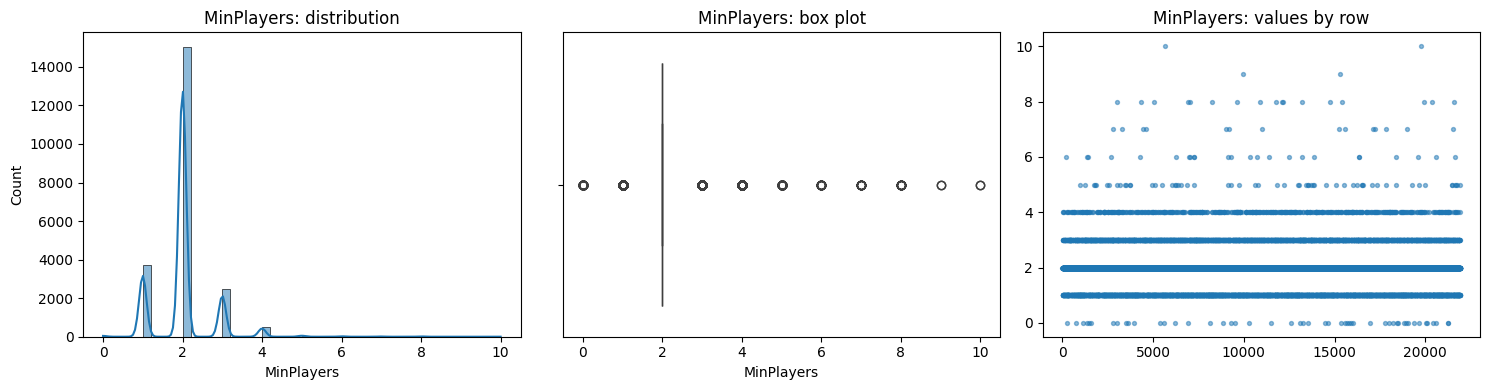

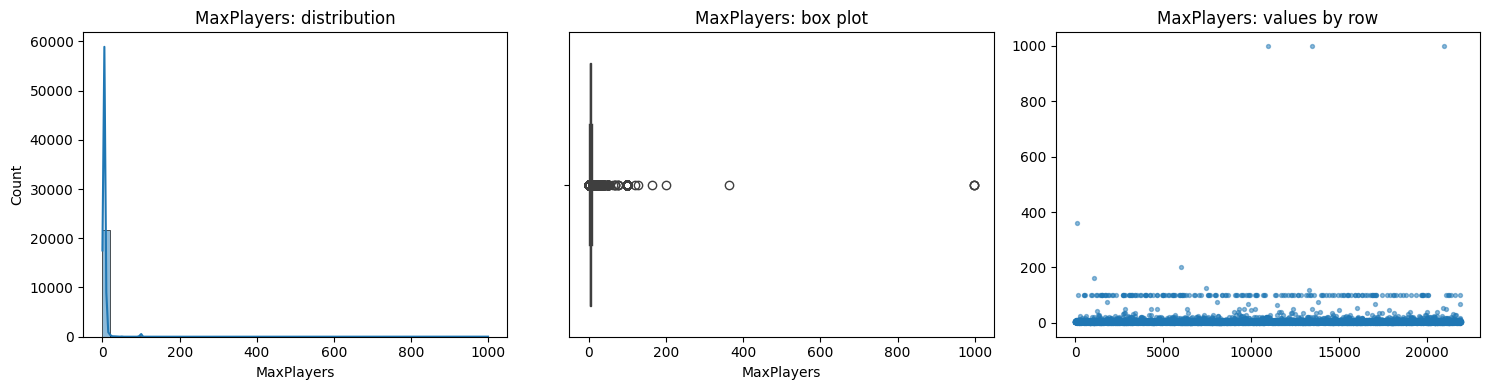

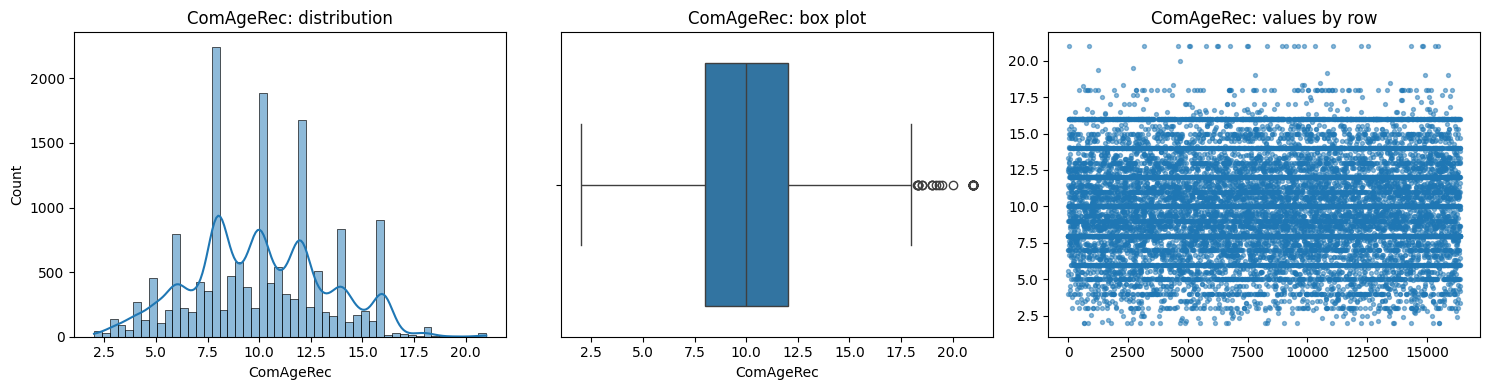

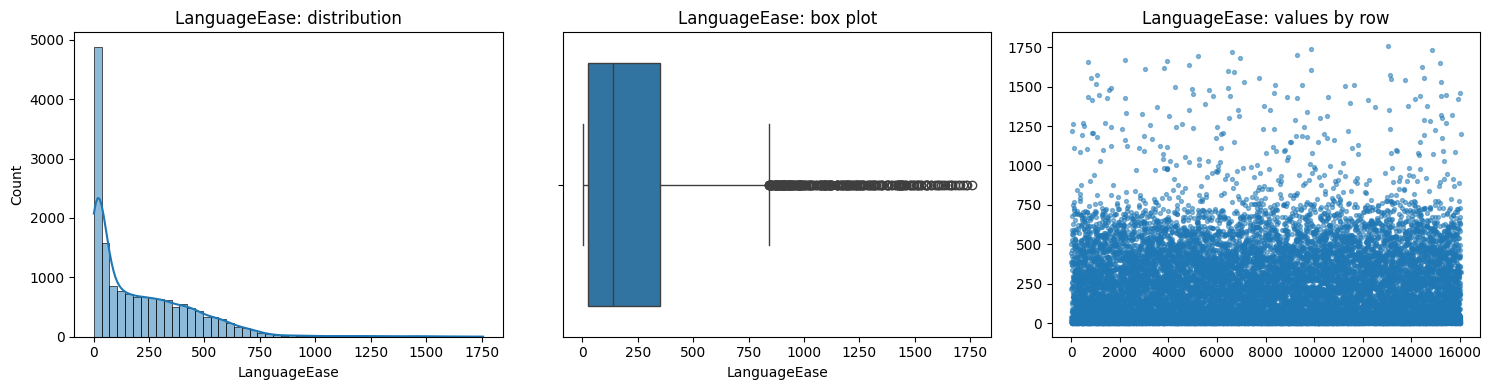

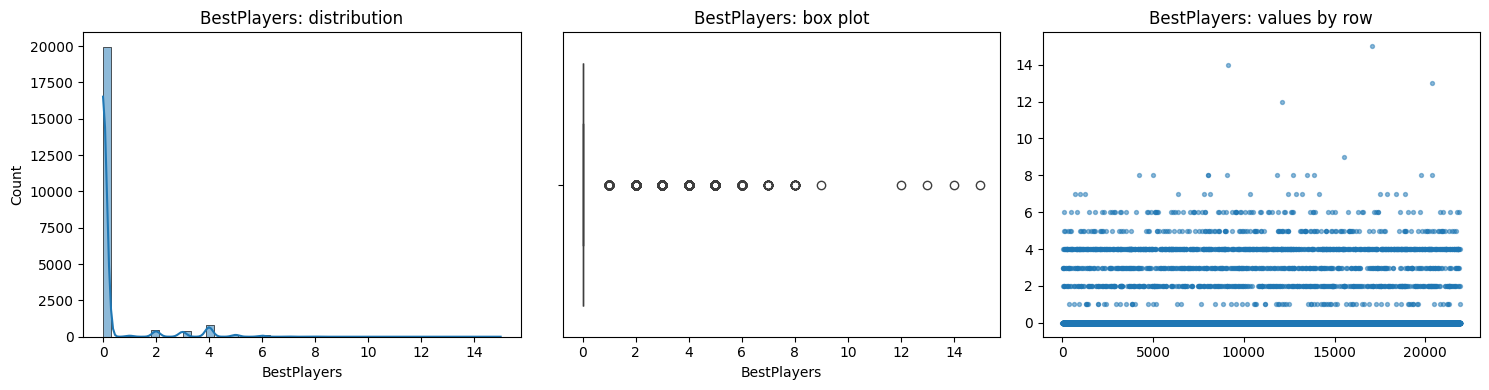

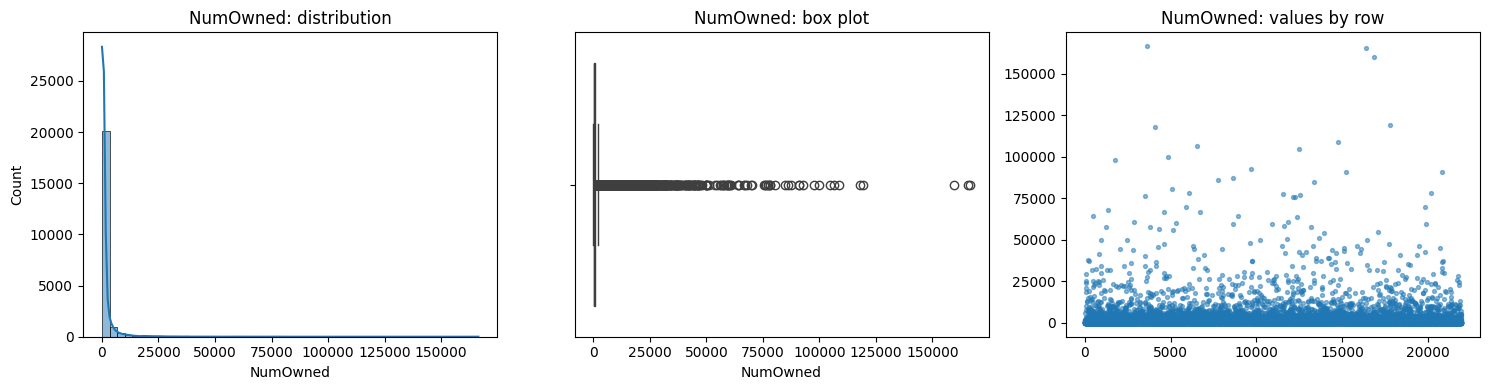

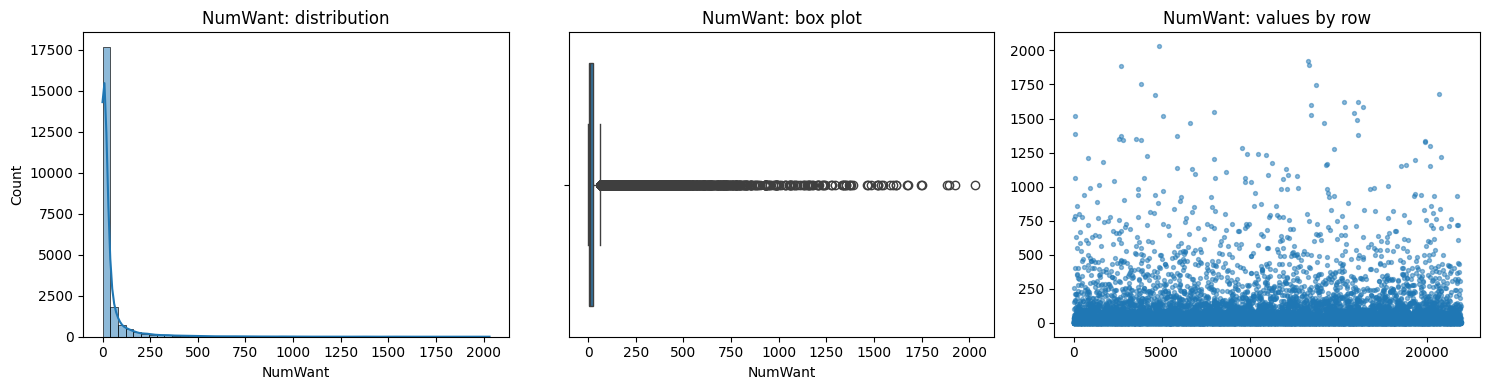

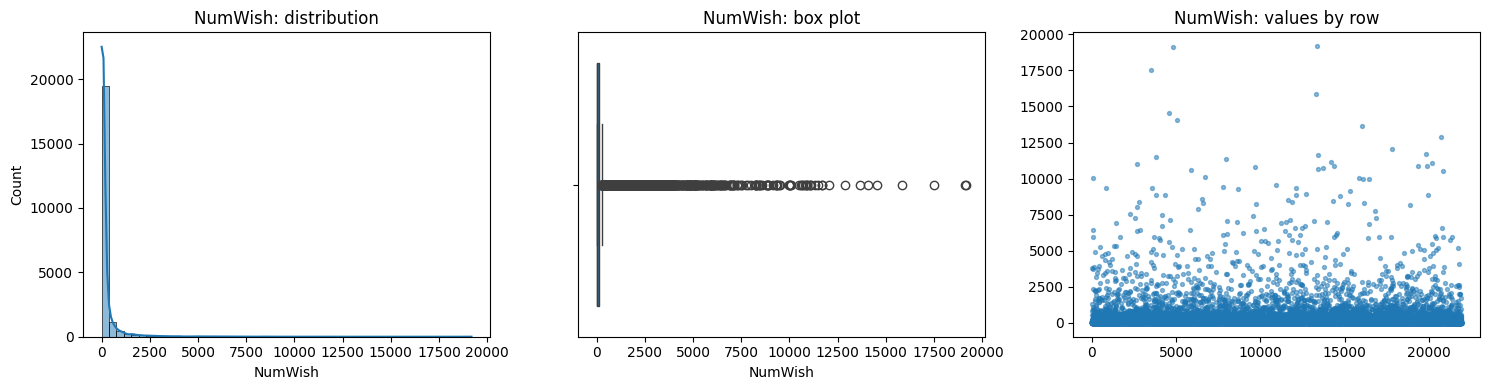

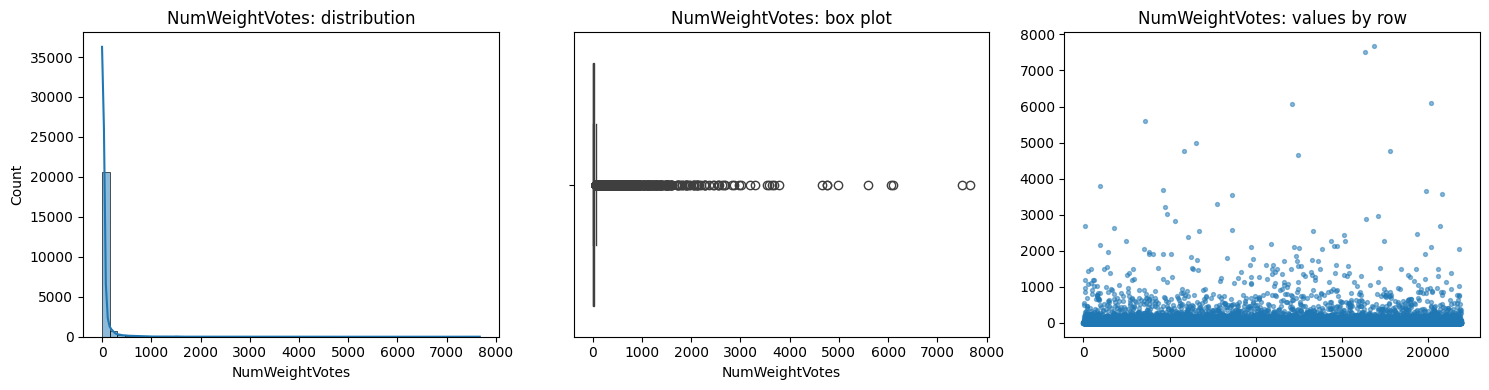

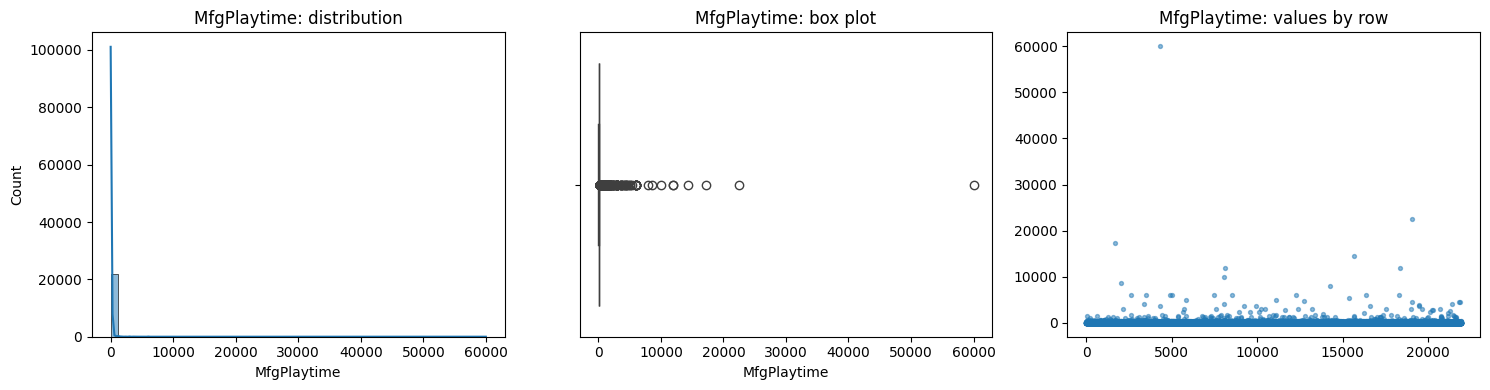

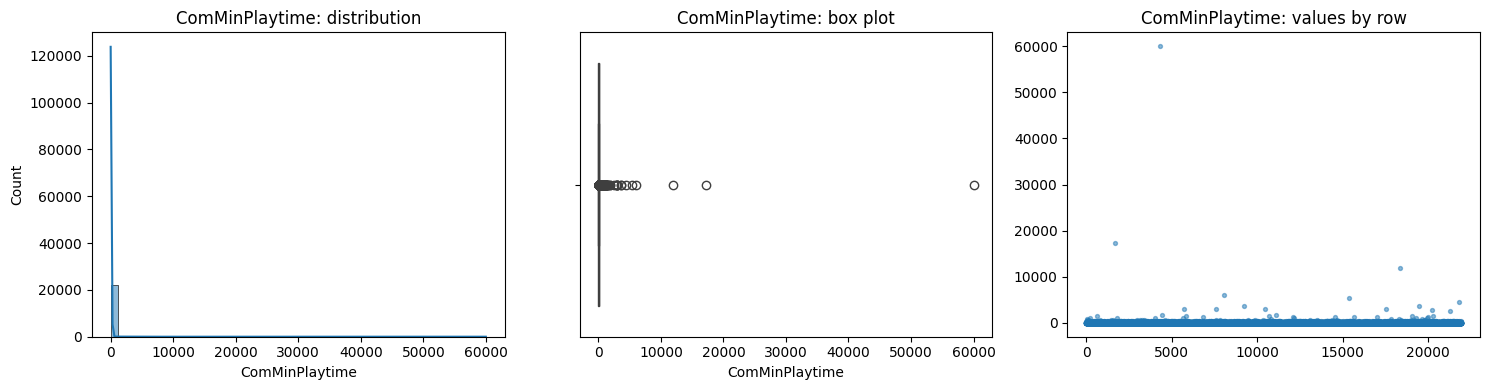

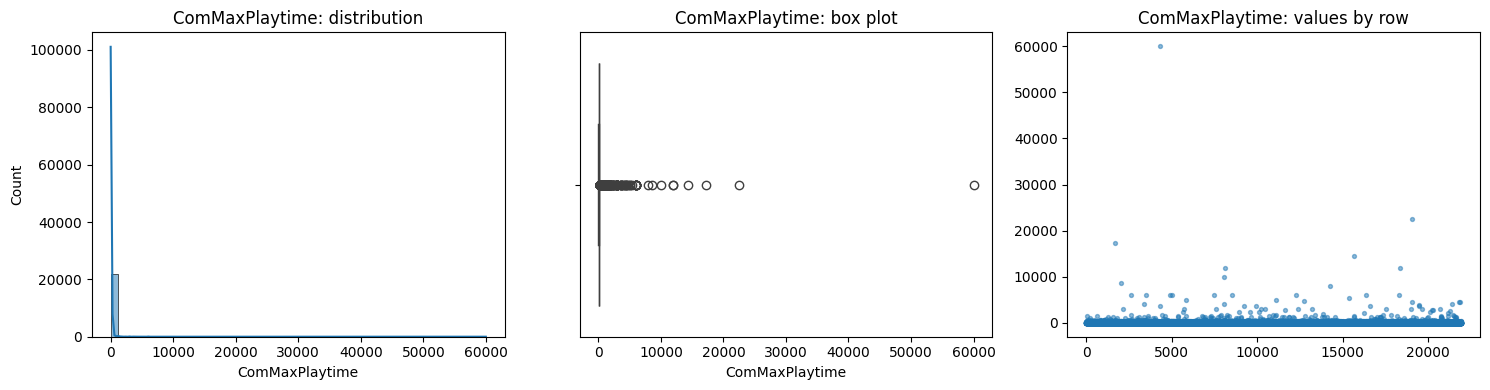

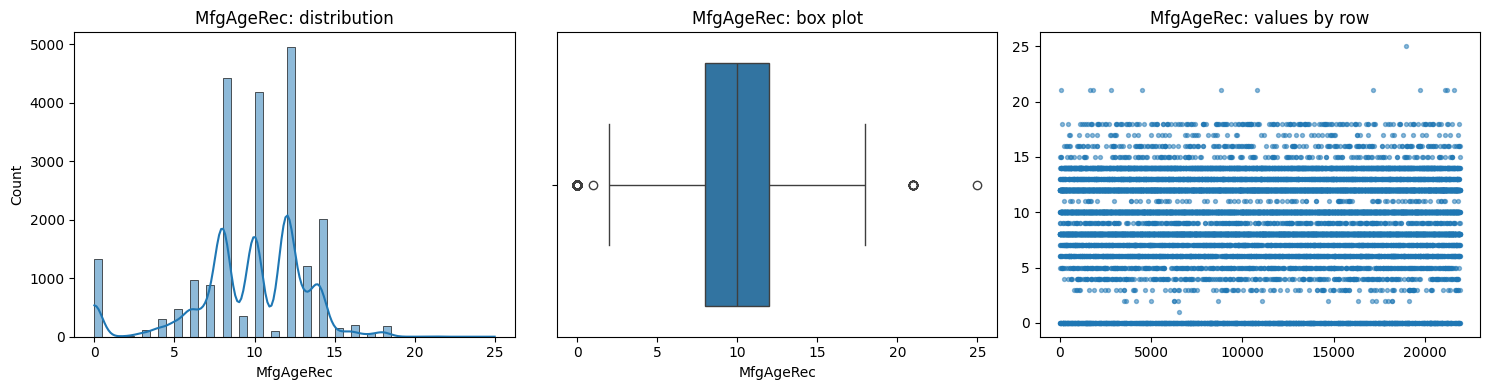

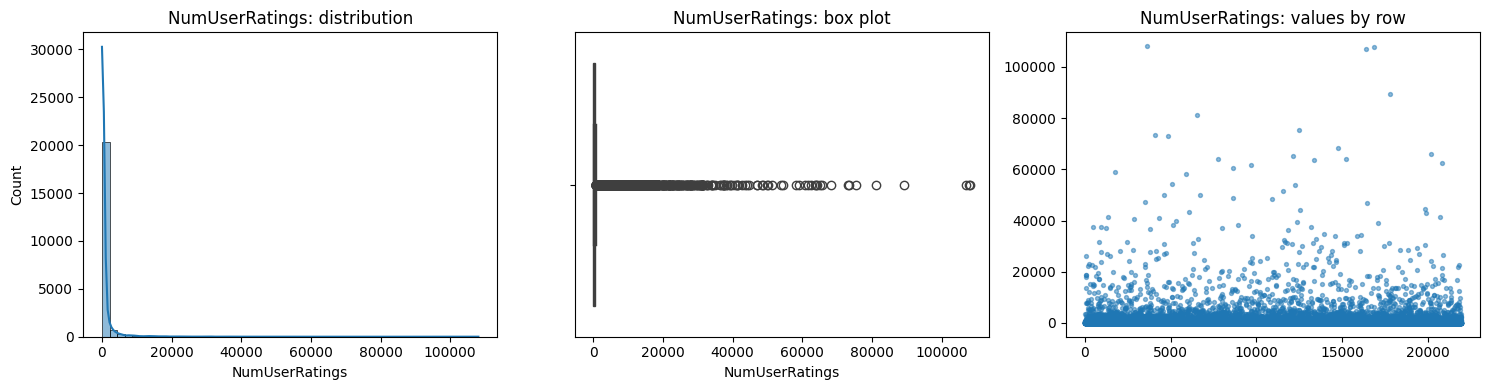

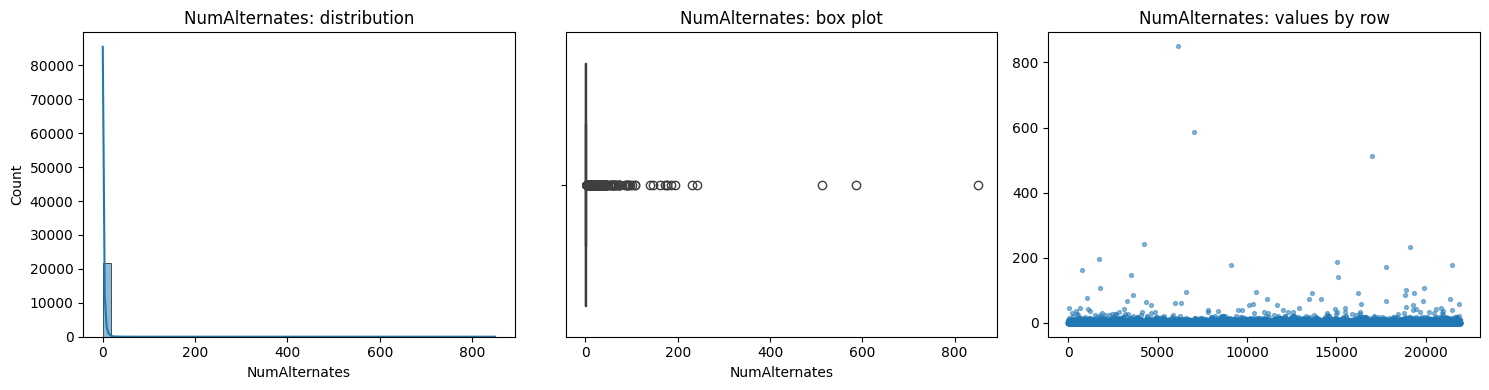

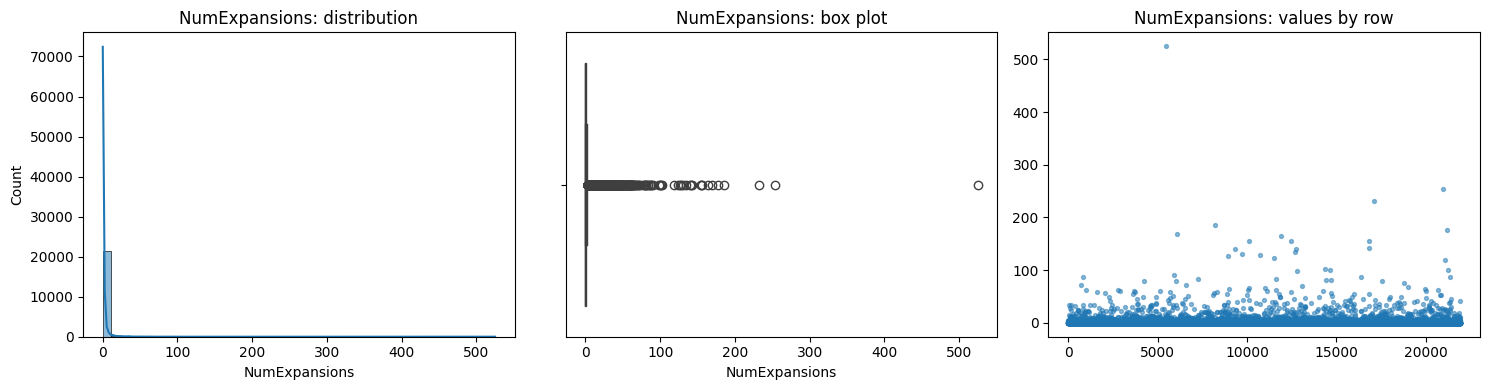

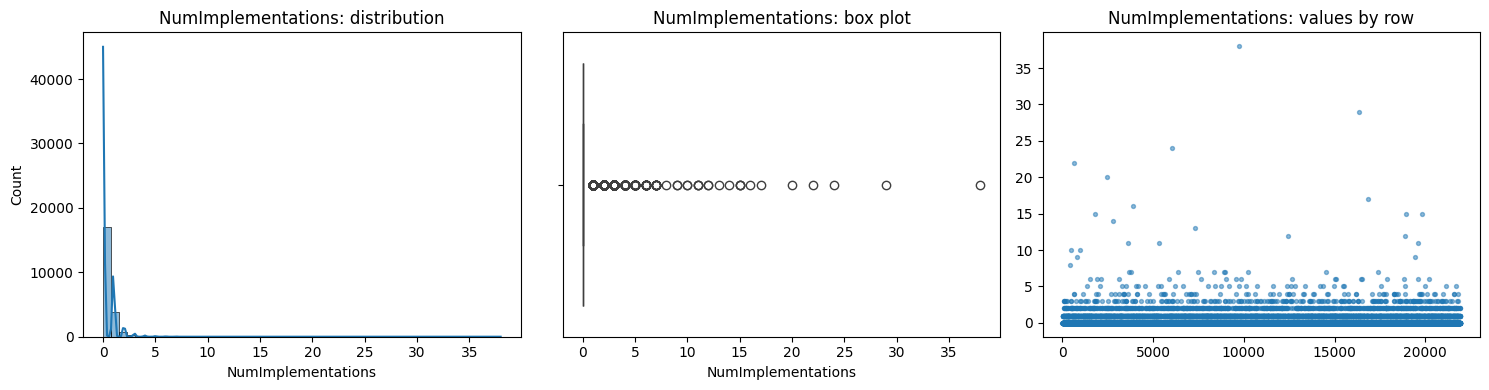

In [8]:
def plot_numeric_distribution(frame, col, bins=50):
    s = pd.to_numeric(frame[col], errors="coerce").dropna()
    if s.empty:
        return
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(s, bins=bins, kde=True, ax=axes[0])
    axes[0].set_title(f"{col}: distribution")
    sns.boxplot(x=s, ax=axes[1])
    axes[1].set_title(f"{col}: box plot")
    axes[2].scatter(np.arange(len(s)), s, s=8, alpha=0.5)
    axes[2].set_title(f"{col}: values by row")
    plt.tight_layout()
    plt.show()

for col in df.select_dtypes(include=np.number).columns:
    if col != "BGGId" and not col.startswith("Rank:"):
        plot_numeric_distribution(df, col)

#### Repeated values in nominal/text attributes

In [9]:
# Name duplicates and publication-year check.
name_counts = df["Name"].value_counts()
duplicate_names = name_counts[name_counts > 1]
df_dupes = df[df["Name"].isin(duplicate_names.index)]

group_results = []
for name, group in df_dupes.groupby("Name", observed=False):
    years = group["YearPublished"].dropna().unique()
    all_years_different = len(years) == len(group["YearPublished"].dropna()) and len(years) > 1
    group_results.append((name, all_years_different))

name_check = pd.DataFrame(group_results, columns=["Name", "AllYearsDifferent"])
print("Duplicated Name values:", len(duplicate_names))
print("Groups with all publication years different:", int(name_check["AllYearsDifferent"].sum()))
print("Groups requiring manual inspection:", int((~name_check["AllYearsDifferent"]).sum()))

Duplicated Name values: 369
Groups with all publication years different: 363
Groups requiring manual inspection: 6


In [10]:
# Description duplicates: lightweight entity-resolution checks used in the project.
desc_counts = df["Description"].value_counts()
duplicate_desc = desc_counts[desc_counts > 1].index
df_dup_desc = df[df["Description"].isin(duplicate_desc)][["Description", "Name"]].copy()

def same_prefix_pattern(names):
    for i, n1 in enumerate(names):
        for n2 in names[i+1:]:
            m = re.match(r"^(.+?)(:|-)\s*", str(n1))
            if m:
                p = m.group(1).strip().lower()
                if str(n2).lower().startswith(p + ":") or str(n2).lower().startswith(p + "-"):
                    return True
    return False

def differs_only_by_number(names):
    norm = [re.sub(r"\d+", "<NUM>", str(n).lower()) for n in names]
    return len(set(norm)) < len(names)

def has_version_or_edition_almost_all(names):
    pat = re.compile(r"(version|edition)", re.IGNORECASE)
    matches = [bool(pat.search(str(n))) for n in names]
    return sum(not x for x in matches) <= 1

results = []
for desc, group in df_dup_desc.groupby("Description", observed=False):
    names = group["Name"].dropna().tolist()
    if len(names) < 2:
        continue
    a = same_prefix_pattern(names)
    b = differs_only_by_number(names)
    c = has_version_or_edition_almost_all(names)
    results.append((desc, a, b, c, a or b or c))

desc_er = pd.DataFrame(results, columns=["Description", "PrefixPattern", "DiffersByNumber", "EditionPattern", "AnyCondition"])
print("Duplicated Description values:", len(duplicate_desc))
if len(desc_er):
    print("Groups satisfying at least one ER condition:", f"{desc_er['AnyCondition'].mean():.1%}")

Duplicated Description values: 15
Groups satisfying at least one ER condition: 80.0%


In [11]:
# ImagePath duplicates.
image_dupes = df[df.duplicated(subset=["ImagePath"], keep=False) & df["ImagePath"].notna()]
print("Duplicated ImagePath values:", image_dupes["ImagePath"].nunique())

Duplicated ImagePath values: 4


## 1.4 Assessing Data Quality

### 1.4.1 Missing Values

In [12]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Pct": df.isna().mean() * 100,
}).sort_values("Missing_Count", ascending=False)
missing_summary[missing_summary["Missing_Count"] > 0]

,Missing_Count,Missing_Pct
Family,15262,69.610034
LanguageEase,5891,26.868871
ComAgeRec,5530,25.222349
ImagePath,17,0.077537
Description,1,0.004561


### 1.4.2 Semantic Inconsistencies and Wrong Data

In [13]:
# Track cells changed by the cleaning procedure.
df["ArtificialImputations"] = [[] for _ in range(len(df))]

def add_flag(mask, column_name):
    df.loc[mask, "ArtificialImputations"] = df.loc[mask, "ArtificialImputations"].apply(
        lambda flags: flags + [column_name]
    )

#### YearPublished

In [14]:
RUN_BGG_SCRAPING = False

def fetch_bgg_year(bgg_id, retries=3):
    import requests
    url = f"https://boardgamegeek.com/boardgame/{bgg_id}"
    headers = {"User-Agent": "Mozilla/5.0"}
    for _ in range(retries):
        try:
            r = requests.get(url, headers=headers, timeout=10)
            if r.status_code != 200:
                return None
            m = re.search(r"GEEK\.geekitemPreload\s*=\s*(\{.*?\});", r.text, flags=re.DOTALL)
            if not m:
                return None
            item = json.loads(m.group(1)).get("item", {})
            year = item.get("yearpublished")
            if year is None:
                for entry in item.get("itemdata", []):
                    if entry.get("fieldname") == "yearpublished":
                        year = entry.get("value")
                        break
            time.sleep(0.4)
            return int(year) if year is not None else None
        except Exception:
            time.sleep(1)
    return None

mask_year_zero = df["YearPublished"].eq(0)
print("YearPublished = 0 before correction:", int(mask_year_zero.sum()))

if RUN_BGG_SCRAPING:
    corrected = 0
    for idx, row in df.loc[mask_year_zero, ["BGGId"]].iterrows():
        year = fetch_bgg_year(row["BGGId"])
        if year not in (None, 0):
            df.at[idx, "YearPublished"] = year
            corrected += 1
    print("Recovered from BGG:", corrected)

# Unresolved zero years are treated as missing, as in the report.
remaining_zero = df["YearPublished"].eq(0)
df.loc[remaining_zero, "YearPublished"] = pd.NA
add_flag(remaining_zero, "YearPublished")
print("Unresolved YearPublished values set to NaN:", int(remaining_zero.sum()))

YearPublished = 0 before correction: 193
Unresolved YearPublished values set to NaN: 193


#### GameWeight and ComWeight

In [15]:
zero_weight = df["GameWeight"].eq(0)
print("GameWeight = 0:", int(zero_weight.sum()))
print("Same rows with NumWeightVotes = 0:", int((zero_weight & df["NumWeightVotes"].eq(0)).sum()))

# Zero means no votes rather than a valid 1–5 score.
df.loc[zero_weight, "GameWeight"] = pd.NA
add_flag(zero_weight, "GameWeight")

# ComWeight is retained temporarily for correlation analysis and later removed.
print("ComWeight values above 5:", int((pd.to_numeric(df["ComWeight"], errors="coerce") > 5).sum()))

GameWeight = 0: 506
Same rows with NumWeightVotes = 0: 506
ComWeight values above 5: 13


#### MinPlayers and MaxPlayers

In [16]:
# Deterministic rules documented in the report.
minp = pd.to_numeric(df["MinPlayers"], errors="coerce")
maxp = pd.to_numeric(df["MaxPlayers"], errors="coerce")

mask_min_gt_max = minp > maxp
mask_min_zero_max_pos = minp.eq(0) & maxp.gt(0)
mask_both_zero = minp.eq(0) & maxp.eq(0)

# Min > Max -> use the minimum value as the corrected maximum.
df.loc[mask_min_gt_max, "MaxPlayers"] = df.loc[mask_min_gt_max, "MinPlayers"]
add_flag(mask_min_gt_max, "MaxPlayers")

# Min = 0, Max > 0 -> conservative valid minimum of one player.
df.loc[mask_min_zero_max_pos, "MinPlayers"] = 1
add_flag(mask_min_zero_max_pos, "MinPlayers")

# Both zero -> genuinely missing.
df.loc[mask_both_zero, ["MinPlayers", "MaxPlayers"]] = pd.NA
add_flag(mask_both_zero, "MinPlayers")
add_flag(mask_both_zero, "MaxPlayers")

print("Min > Max corrected:", int(mask_min_gt_max.sum()))
print("Min = 0 and Max > 0 corrected:", int(mask_min_zero_max_pos.sum()))
print("Both zero -> NaN:", int(mask_both_zero.sum()))

Min > Max corrected: 132
Min = 0 and Max > 0 corrected: 9
Both zero -> NaN: 41


#### Community play time

In [17]:
min_col, max_col = "ComMinPlaytime", "ComMaxPlaytime"

print("MfgPlaytime identical to ComMaxPlaytime:", bool((df["MfgPlaytime"] == df["ComMaxPlaytime"]).all()))

mask_swap = (df[min_col] > df[max_col]) & df[max_col].ne(0)
df.loc[mask_swap, [min_col, max_col]] = df.loc[mask_swap, [max_col, min_col]].to_numpy()

mask_min_zero = df[min_col].eq(0) & df[max_col].ne(0)
df.loc[mask_min_zero, min_col] = df.loc[mask_min_zero, max_col]

mask_max_zero = df[max_col].eq(0) & df[min_col].ne(0)
df.loc[mask_max_zero, max_col] = df.loc[mask_max_zero, min_col]

mask_both_zero = df[min_col].eq(0) & df[max_col].eq(0)
df.loc[mask_both_zero, [min_col, max_col]] = pd.NA

for mask in [mask_swap, mask_min_zero, mask_max_zero, mask_both_zero]:
    add_flag(mask, min_col)
    add_flag(mask, max_col)

print("Swapped min/max:", int(mask_swap.sum()))
print("Filled missing minimum from maximum:", int(mask_min_zero.sum()))
print("Filled missing maximum from minimum:", int(mask_max_zero.sum()))
print("Both zero -> NaN:", int(mask_both_zero.sum()))

MfgPlaytime identical to ComMaxPlaytime: True
Swapped min/max: 4
Filled missing minimum from maximum: 19
Filled missing maximum from minimum: 147
Both zero -> NaN: 633


#### MfgAgeRec

In [18]:
# 0 is not a valid manufacturer-recommended age.
df["MfgAgeRec"] = pd.to_numeric(df["MfgAgeRec"], errors="coerce").astype(float)
mask_age_zero = df["MfgAgeRec"].eq(0)
mask_com_valid = df["ComAgeRec"].notna() & df["ComAgeRec"].ne(0)
mask_direct = mask_age_zero & mask_com_valid

df.loc[mask_direct, "MfgAgeRec"] = pd.to_numeric(df.loc[mask_direct, "ComAgeRec"], errors="coerce")
add_flag(mask_direct, "MfgAgeRec")

print("MfgAgeRec = 0 initially:", int(mask_age_zero.sum()))
print("Fixed directly with ComAgeRec:", int(mask_direct.sum()))

MfgAgeRec = 0 initially: 1325
Fixed directly with ComAgeRec: 995


In [19]:
# Estimate the remaining ages from Family, active categories and similar GameWeight (±0.5).
base_age = df["MfgAgeRec"].replace(0, np.nan)

family_age = (
    pd.DataFrame({"Family": df["Family"], "AgeBase": base_age})
    .dropna()
    .groupby("Family", observed=False)["AgeBase"]
    .mean()
)

cat_cols = [c for c in df.columns if c.startswith("Cat:")]
cat_means = {c: base_age[df[c].astype("Int64").eq(1)].mean() for c in cat_cols}

valid_weight_age = pd.DataFrame({"GameWeight": pd.to_numeric(df["GameWeight"], errors="coerce"), "AgeBase": base_age}).dropna()

def estimate_age(row):
    estimates = []
    fam = row.get("Family")
    if pd.notna(fam) and fam in family_age.index:
        estimates.append(float(family_age.loc[fam]))

    active = [c for c in cat_cols if pd.notna(row.get(c)) and bool(row.get(c))]
    cat_vals = [cat_means[c] for c in active if pd.notna(cat_means[c])]
    if cat_vals:
        estimates.append(float(np.mean(cat_vals)))

    gw = pd.to_numeric(pd.Series([row.get("GameWeight")]), errors="coerce").iloc[0]
    if pd.notna(gw):
        neigh = valid_weight_age.loc[(valid_weight_age["GameWeight"] - gw).abs() <= 0.5, "AgeBase"]
        if len(neigh):
            estimates.append(float(neigh.mean()))

    return np.mean(estimates) if estimates else np.nan

mask_remaining_age = df["MfgAgeRec"].isna() | df["MfgAgeRec"].eq(0)
estimated_age = df.loc[mask_remaining_age].apply(estimate_age, axis=1)
df.loc[mask_remaining_age, "MfgAgeRec"] = estimated_age.values
add_flag(mask_remaining_age & df["MfgAgeRec"].notna(), "MfgAgeRec")

# Age is semantically discrete; round only after the estimation step.
df["MfgAgeRec"] = pd.to_numeric(df["MfgAgeRec"], errors="coerce").round()
print("Remaining missing MfgAgeRec:", int(df["MfgAgeRec"].isna().sum()))

Remaining missing MfgAgeRec: 13


#### Non-informative / semantically inconsistent attributes

In [20]:
print("BestPlayers = 0:", f"{df['BestPlayers'].eq(0).mean():.2%}")
print("GoodPlayers = []:", f"{df['GoodPlayers'].astype('string').eq('[]').mean():.2%}")
print("NumComments unique values:", df["NumComments"].nunique(dropna=False))
print("LanguageEase missing:", f"{df['LanguageEase'].isna().mean():.2%}")

BestPlayers = 0: 90.96%
GoodPlayers = []: 90.97%
NumComments unique values: 1
LanguageEase missing: 26.87%


### 1.4.3 Outlier Detection

In [21]:
# YearPublished: negative years were manually checked in the project and retained as semantically valid.
print("Smallest YearPublished values:")
display(pd.to_numeric(df["YearPublished"], errors="coerce").nsmallest(10))

# Standardize open-ended MaxPlayers cap values.
print("MaxPlayers >= 99 before standardization:")
display(df.loc[pd.to_numeric(df["MaxPlayers"], errors="coerce") >= 99, "MaxPlayers"].value_counts().sort_index())
df["MaxPlayers"] = df["MaxPlayers"].replace({100: 99, 999: 99})

# Extreme playtimes were inspected but retained.
print("ComMaxPlaytime > 10,000:", int((pd.to_numeric(df["ComMaxPlaytime"], errors="coerce") > 10000).sum()))

Smallest YearPublished values:


1173     -3500
16155    -3000
18254    -3000
21325    -3000
21623    -2600
20577    -2200
4362     -1400
14126    -1400
9492     -1300
806       -200
Name: YearPublished, dtype: Int16

MaxPlayers >= 99 before standardization:


MaxPlayers
99     154
100     19
120      1
127      1
163      1
200      1
362      1
999      3
Name: count, dtype: Int64

ComMaxPlaytime > 10,000: 6


In [22]:
# Operational clipping used for downstream analyses, as stated in the report.
# Keep the raw cleaned values in separate columns for traceability.
df["YearPublished_raw_clean"] = df["YearPublished"]
df["MaxPlayers_raw_clean"] = df["MaxPlayers"]

df["YearPublished"] = pd.to_numeric(df["YearPublished"], errors="coerce").clip(lower=1949)
df["MaxPlayers"] = pd.to_numeric(df["MaxPlayers"], errors="coerce").clip(upper=30)

## 1.5 Pairwise Correlation

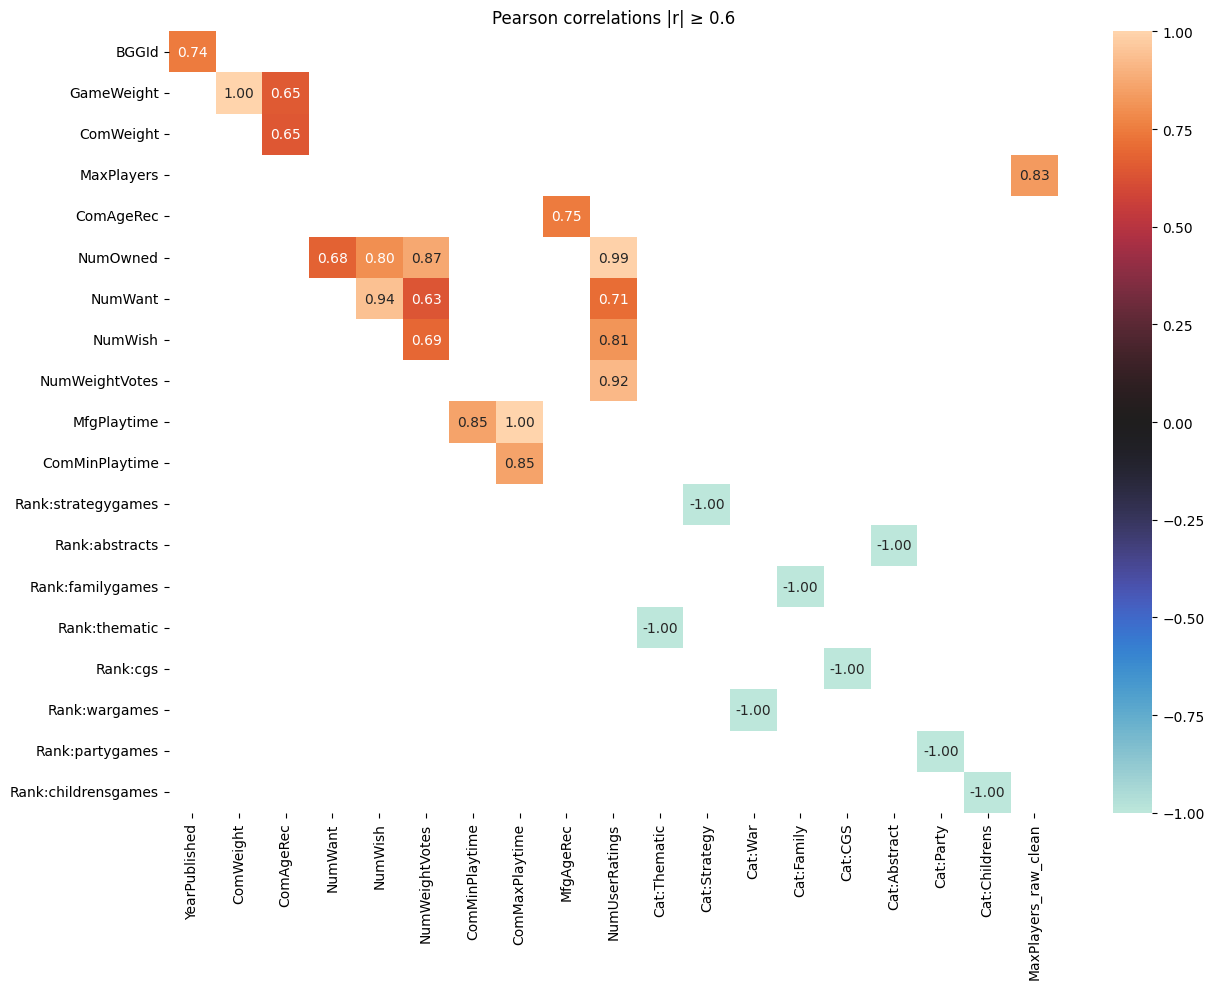

In [23]:
# Pearson correlation matrix; threshold used in the report to focus inspection.
corr = df.corr(numeric_only=True)
threshold = 0.60
masked = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong = masked.where(masked.abs() >= threshold).dropna(how="all").dropna(axis=1, how="all")

plt.figure(figsize=(13, 10))
sns.heatmap(strong, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0)
plt.title(f"Pearson correlations |r| ≥ {threshold}")
plt.tight_layout()
plt.show()

In [24]:
# Pairs above the corrective-action threshold used in the report (> 0.8).
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = (
    upper.stack()
    .rename("correlation")
    .loc[lambda s: s.abs() > 0.8]
    .sort_values(key=np.abs, ascending=False)
)
high_pairs

Rank:cgs             Cat:CGS                -0.999992
Rank:partygames      Cat:Party              -0.999962
MfgPlaytime          ComMaxPlaytime          0.999953
Rank:childrensgames  Cat:Childrens          -0.999927
Rank:abstracts       Cat:Abstract           -0.999880
Rank:thematic        Cat:Thematic           -0.999854
Rank:familygames     Cat:Family             -0.999421
Rank:strategygames   Cat:Strategy           -0.999415
Rank:wargames        Cat:War                -0.998480
GameWeight           ComWeight               0.997412
NumOwned             NumUserRatings          0.985474
NumWant              NumWish                 0.939758
NumWeightVotes       NumUserRatings          0.917185
NumOwned             NumWeightVotes          0.874876
ComMinPlaytime       ComMaxPlaytime          0.854666
MfgPlaytime          ComMinPlaytime          0.854592
MaxPlayers           MaxPlayers_raw_clean    0.831218
NumWish              NumUserRatings          0.814348
Name: correlation, dtype: fl

## 1.6 Data Transformation: Feature Engineering and Elimination of Attributes

#### AvgPlaytime and NumDemand

In [25]:
df["AvgPlaytime"] = df[["ComMinPlaytime", "ComMaxPlaytime"]].mean(axis=1)
df["NumDemand"] = pd.to_numeric(df["NumWish"], errors="coerce").fillna(0) + pd.to_numeric(df["NumWant"], errors="coerce").fillna(0)

#### Rank–Category consistency

In [26]:
rank_cat_pairs = {
    "Rank:thematic": "Cat:Thematic",
    "Rank:strategygames": "Cat:Strategy",
    "Rank:wargames": "Cat:War",
    "Rank:familygames": "Cat:Family",
    "Rank:cgs": "Cat:CGS",
    "Rank:abstracts": "Cat:Abstract",
    "Rank:partygames": "Cat:Party",
    "Rank:childrensgames": "Cat:Childrens",
}

consistency = []
for rank_col, cat_col in rank_cat_pairs.items():
    rank = pd.to_numeric(df[rank_col], errors="coerce")
    cat = pd.to_numeric(df[cat_col], errors="coerce")
    wrong_placeholder = ((rank == 21926) & (cat == 1)).sum()
    wrong_valid = ((rank != 21926) & (cat == 0)).sum()
    consistency.append((rank_col, cat_col, int(wrong_placeholder), int(wrong_valid)))

pd.DataFrame(consistency, columns=["Rank", "Category", "Rank21926_Cat1", "ValidRank_Cat0"])

,Rank,Category,Rank21926_Cat1,ValidRank_Cat0
0,Rank:thematic,Cat:Thematic,0,0
1,Rank:strategygames,Cat:Strategy,0,0
2,Rank:wargames,Cat:War,0,0
3,Rank:familygames,Cat:Family,0,0
4,Rank:cgs,Cat:CGS,0,0
5,Rank:abstracts,Cat:Abstract,0,0
6,Rank:partygames,Cat:Party,0,0
7,Rank:childrensgames,Cat:Childrens,0,0


#### Aggregated Ranking feature

In [27]:
# Each valid category-specific rank is normalized to [0,1] with the direction
# inverted so that higher values correspond to better ranks. When a game has
# several valid category ranks, their normalized values are averaged.

normalized_ranks = []
for rank_col in rank_cat_pairs:
    s = pd.to_numeric(df[rank_col], errors="coerce").replace(21926, np.nan)
    mn, mx = s.min(), s.max()
    norm = 1 - (s - mn) / (mx - mn)
    normalized_ranks.append(norm.rename(rank_col))

rank_matrix = pd.concat(normalized_ranks, axis=1)
df["Ranking"] = rank_matrix.mean(axis=1, skipna=True)
ranking_mean = df["Ranking"].mean()
df["Ranking"] = df["Ranking"].fillna(ranking_mean)

rating_numeric = df["Rating"].astype("string").str.title().map({"Low": 1, "Medium": 2, "High": 3})
print(f"Observed Ranking coverage before imputation: {rank_matrix.notna().any(axis=1).mean():.2%}")
print(f"Mean used for Ranking imputation: {ranking_mean:.6f}")
print(f"Ranking vs Rating correlation (observed rows): {rank_matrix.mean(axis=1, skipna=True).corr(rating_numeric):.3f}")
print(f"Ranking vs Rating correlation (after imputation): {df['Ranking'].corr(rating_numeric):.3f}")

Observed Ranking coverage before imputation: 48.99%
Mean used for Ranking imputation: 0.499238
Ranking vs Rating correlation (observed rows): 0.675
Ranking vs Rating correlation (after imputation): 0.466


#### SemanticString

In [28]:
# Name punctuation is removed; Description and Family are concatenated when available.
name_clean = df["Name"].astype("string").fillna("").str.replace(r"[^\w\s]", " ", regex=True)
description = df["Description"].astype("string").fillna("")
family = df["Family"].astype("string").fillna("")

df["SemanticString"] = (
    name_clean + " " + description + " " + family
).str.replace(r"\s+", " ", regex=True).str.strip()

#### Log transformations

In [29]:
# Strongly right-skewed count/duration variables are transformed with log1p.
log_cols = [
    "AvgPlaytime", "NumOwned", "NumDemand",
    "NumAlternates", "NumExpansions", "NumImplementations",
]
for col in log_cols:
    df[col] = np.log1p(pd.to_numeric(df[col], errors="coerce"))

### Nan Handling and studying

In [30]:
# ============================================================
# ANALISI DELLE ARTIFICIAL IMPUTATIONS ORIGINALI (NON PULITE)
# ============================================================

# 1) Normalizza la colonna per sicurezza
df["ArtificialImputations"] = df["ArtificialImputations"].apply(
    lambda x: x if isinstance(x, list) else []
)

# 2) Conta il numero totale di flag originali per riga
flag_count_raw = df["ArtificialImputations"].apply(len)

# 3) Statistiche di base
total_flags_raw = flag_count_raw.sum()
N = len(df)

print("\n===== ARTIFICIAL IMPUTATIONS ORIGINALI (SENZA PULIZIA) =====\n")
print(f"Totale righe: {N}")
print(f"Totale flag (tutti, senza rimuovere quelli sulle colonne NaN): {total_flags_raw}\n")

# 4) Distribuzione dei flag
flag_dist_raw = flag_count_raw.value_counts().sort_index()

print("===== DISTRIBUZIONE DEI FLAG (NON PULITI) PER RIGA =====\n")
for k, count in flag_dist_raw.items():
    print(f"{count:5d} righe → {k} flag ({count/N:.4f})")

# 5) Probabilità cumulative
max_k = flag_count_raw.max()
P_ge_raw = {k: (flag_count_raw >= k).mean() for k in range(1, max_k+1)}

print("\n===== PROBABILITÀ CUMULATIVE (NON PULITE) =====\n")
for k in range(1, max_k+1):
    print(f"P(≥{k} flag) = {P_ge_raw[k]:.6f}")

# 6) Tabella completa (ordinata)
print("\n===== TABELLA ORDINATA DELLA DISTRIBUZIONE =====\n")
print(flag_dist_raw)


===== ARTIFICIAL IMPUTATIONS ORIGINALI (SENZA PULIZIA) =====

Totale righe: 21925
Totale flag (tutti, senza rimuovere quelli sulle colonne NaN): 3840

===== DISTRIBUZIONE DEI FLAG (NON PULITI) PER RIGA =====

19365 righe → 0 flag (0.8832)
 1666 righe → 1 flag (0.0760)
  591 righe → 2 flag (0.0270)
  245 righe → 3 flag (0.0112)
   41 righe → 4 flag (0.0019)
    9 righe → 5 flag (0.0004)
    8 righe → 6 flag (0.0004)

===== PROBABILITÀ CUMULATIVE (NON PULITE) =====

P(≥1 flag) = 0.116762
P(≥2 flag) = 0.040775
P(≥3 flag) = 0.013820
P(≥4 flag) = 0.002645
P(≥5 flag) = 0.000775
P(≥6 flag) = 0.000365

===== TABELLA ORDINATA DELLA DISTRIBUZIONE =====

ArtificialImputations
0    19365
1     1666
2      591
3      245
4       41
5        9
6        8
Name: count, dtype: int64


In [31]:
cols = [
    "BGGId", "Name", "Description", "YearPublished", "GameWeight",
    "MinPlayers", "MaxPlayers", "NumOwned", "NumWant", "NumWish",
    "NumWeightVotes", "ComMinPlaytime", "ComMaxPlaytime",
    "MfgAgeRec", "NumUserRatings", "NumAlternates",
    "NumExpansions", "NumImplementations", "IsReimplementation",
    "Kickstarted", "Cat:Thematic", "Cat:Strategy", "Cat:War",
    "Cat:Family", "Cat:CGS", "Cat:Abstract", "Cat:Party",
    "Cat:Childrens", "Rating"
]

df2 = df[cols]
N = len(df)
valid_cols = set(cols)

# ============================================================
# 1) CREA UNA VERSIONE PULITA DEI FLAG → *NON* MODIFICA QUELLI ORIGINALI
# ============================================================

# garantisce che ArtificialImputations sia sempre una lista
df["ArtificialImputations"] = df["ArtificialImputations"].apply(
    lambda x: x if isinstance(x, list) else []
)

def clean_flags(row_flags, row_vals):
    """Rimuove solo i flag relativi a colonne che sono NaN in quella riga."""
    return [c for c in row_flags if c in valid_cols and not pd.isna(row_vals[c])]

# nuova colonna pulita
df["AI_clean"] = df.apply(
    lambda r: clean_flags(r["ArtificialImputations"], r[cols]),
    axis=1
)

# set per riga + conta flag
df["AI_clean_set"] = df["AI_clean"].apply(set)
flag_count = df["AI_clean_set"].apply(len)

# ============================================================
# 2) DISTRIBUZIONE DEI NaN
# ============================================================

nan_per_row = df2.isna().sum(axis=1)
nan_dist = nan_per_row.value_counts().sort_index()

print("\n===============================")
print("DISTRIBUZIONE DEI NaN PER RIGA")
print("===============================\n")
print(f"Totale righe: {N}")
print(f"Totale NaN   : {nan_per_row.sum()}\n")

for k, count in nan_dist.items():
    print(f"{count:5d} righe → {k} NaN ({count/N:.4f})")

# ============================================================
# 3) DISTRIBUZIONE DEI FLAG (usando la colonna pulita)
# ============================================================

flag_dist = flag_count.value_counts().sort_index()

print("\n========================================")
print("DISTRIBUZIONE DEI FLAG (AI_clean) PER RIGA")
print("========================================\n")
print(f"Totale righe: {N}")
print(f"Totale flag puliti (somma) : {flag_count.sum()}\n")

for k, count in flag_dist.items():
    print(f"{count:5d} righe → {k} flag ({count/N:.4f})")


DISTRIBUZIONE DEI NaN PER RIGA

Totale righe: 21925
Totale NaN   : 2061

20670 righe → 0 NaN (0.9428)
  590 righe → 1 NaN (0.0269)
  567 righe → 2 NaN (0.0259)
   64 righe → 3 NaN (0.0029)
   25 righe → 4 NaN (0.0011)
    9 righe → 5 NaN (0.0004)

DISTRIBUZIONE DEI FLAG (AI_clean) PER RIGA

Totale righe: 21925
Totale flag puliti (somma) : 1793

20348 righe → 0 flag (0.9281)
 1372 righe → 1 flag (0.0626)
  194 righe → 2 flag (0.0088)
   11 righe → 3 flag (0.0005)


In [32]:
# ============================================================
# DISTRIBUZIONE CONGIUNTA (NaN, Flag) PER RIGA — ORDINATA
# ============================================================

combo_df = pd.DataFrame({
    "NumNaN": nan_per_row,
    "NumFlag": flag_count
})

# Conta quante righe hanno ogni combinazione
combo_counts = combo_df.value_counts().reset_index(name="Count")

# Ordina per numero di righe DESC
combo_counts = combo_counts.sort_values("Count", ascending=False)

print("\n===== DISTRIBUZIONE CONGIUNTA (NaN, Flag) — ORDINATA PER FREQUENZA =====\n")

for _, row in combo_counts.iterrows():
    n_nan = int(row["NumNaN"])
    n_flag = int(row["NumFlag"])
    count = int(row["Count"])
    prob  = count / N
    print(f"{count:5d} righe → {n_nan} NaN e {n_flag} flag ({prob:.4f})")



===== DISTRIBUZIONE CONGIUNTA (NaN, Flag) — ORDINATA PER FREQUENZA =====

19364 righe → 0 NaN e 0 flag (0.8832)
 1129 righe → 0 NaN e 1 flag (0.0515)
  529 righe → 1 NaN e 0 flag (0.0241)
  388 righe → 2 NaN e 0 flag (0.0177)
  170 righe → 2 NaN e 1 flag (0.0078)
  168 righe → 0 NaN e 2 flag (0.0077)
   48 righe → 3 NaN e 0 flag (0.0022)
   44 righe → 1 NaN e 1 flag (0.0020)
   17 righe → 4 NaN e 0 flag (0.0008)
   15 righe → 3 NaN e 1 flag (0.0007)
   15 righe → 1 NaN e 2 flag (0.0007)
    9 righe → 0 NaN e 3 flag (0.0004)
    9 righe → 2 NaN e 2 flag (0.0004)
    7 righe → 4 NaN e 1 flag (0.0003)
    7 righe → 5 NaN e 1 flag (0.0003)
    2 righe → 1 NaN e 3 flag (0.0001)
    2 righe → 5 NaN e 0 flag (0.0001)
    1 righe → 3 NaN e 2 flag (0.0000)
    1 righe → 4 NaN e 2 flag (0.0000)


#### Is the distribution casual?

In [33]:
from math import comb

# ============================================================
# 0) COLONNE DA ANALIZZARE (TUO SET)
# ============================================================

cols = [
    "BGGId", "Name", "Description", "YearPublished", "GameWeight",
    "MinPlayers", "MaxPlayers", "NumOwned", "NumWant", "NumWish",
    "NumWeightVotes", "ComMinPlaytime", "ComMaxPlaytime",
    "MfgAgeRec", "NumUserRatings", "NumAlternates",
    "NumExpansions", "NumImplementations", "IsReimplementation",
    "Kickstarted", "Cat:Thematic", "Cat:Strategy", "Cat:War",
    "Cat:Family", "Cat:CGS", "Cat:Abstract", "Cat:Party",
    "Cat:Childrens", "Rating"
]

df2 = df[cols]
N = len(df2)
C = len(cols)

# ============================================================
# UTILITY: funzione MCAR teorico
# ============================================================

def mcar_distribution(total_events, N, C):
    """Restituisce dizionario {k: P_theo_MCAr} per k = 0..C"""
    p = total_events / (N * C)
    return {
        k: comb(C, k) * (p**k) * ((1-p)**(C-k))
        for k in range(0, C+1)
    }

def cumulative_from_exact(P_exact):
    """Crea P(>=k) da P(k)."""
    keys = sorted(P_exact.keys())
    P_ge = {}
    for k in keys:
        P_ge[k] = 1 - sum(P_exact[j] for j in keys if j < k)
    return P_ge


# ============================================================
# A) ARTIFICIAL IMPUTATIONS — RAW (NON PULITI)
# ============================================================

print("\n" + "="*80)
print("SEZIONE A — ARTIFICIAL IMPUTATIONS ORIGINALI (NON PULITE)")
print("="*80 + "\n")

# normalizzazione sicurezza
df["AI_raw"] = df["ArtificialImputations"].apply(lambda x: x if isinstance(x, list) else [])

flag_count_raw = df["AI_raw"].apply(len)
total_flags_raw = flag_count_raw.sum()

# distribuzione empirica
dist_raw = flag_count_raw.value_counts().sort_index()

print("A.1) Distribuzione empirica dei flag RAW")
for k, count in dist_raw.items():
    print(f"{count:5d} righe → {k} flag_raw ({count/N:.6f})")

# teorico per MCAR
P_raw_theo = mcar_distribution(total_flags_raw, N, C)

print("\nA.2) Confronto EMPIRICO vs TEORICO (MCAR) — tutti i k\n")
for k, count in dist_raw.items():
    p_emp = count / N
    p_theo = P_raw_theo.get(int(k), 0)
    ratio = p_emp / p_theo if p_theo > 0 else np.nan
    print(f"k={k}: P_emp={p_emp:.6f},  P_theo={p_theo:.6f},  Emp/Theo={ratio:.2f}×")

# cumulativi
P_emp_ge_raw = {k: (flag_count_raw >= k).mean() for k in dist_raw.index}
P_theo_ge_raw = cumulative_from_exact(P_raw_theo)

print("\nA.3) Probabilità cumulative")
for k in dist_raw.index:
    print(f"P_emp(≥{k}) = {P_emp_ge_raw[k]:.6f} | P_theo_MCAr(≥{k}) = {P_theo_ge_raw[k]:.6f}")

print("\nA.4) Interpretazione automatica")
print("• Se P_emp >> P_theo_MCAr → i flag non sono distribuiti casualmente.")
print("• I rapporti Emp/Theo mostrano quanto si discosta dal caso MCAR.\n")


# ============================================================
# B) NaN — MCAR TEST COMPLETO
# ============================================================

print("\n" + "="*80)
print("SEZIONE B — I NaN SONO DISTRIBUITI CASUALMENTE (MCAR)?")
print("="*80 + "\n")

nan_per_row = df2.isna().sum(axis=1)
dist_nan = nan_per_row.value_counts().sort_index()
total_nan = nan_per_row.sum()

# teorico MCAR
P_nan_theo = mcar_distribution(total_nan, N, C)

print("B.1) EMPIRICO vs TEORICO per TUTTI i k\n")
for k, count in dist_nan.items():
    p_emp = count/N
    p_theo = P_nan_theo.get(int(k), 0)
    ratio = p_emp/p_theo if p_theo>0 else np.nan
    print(f"k={k}: P_emp={p_emp:.6f} | P_theo_MCAr={p_theo:.6f} | Emp/Theo={ratio:.1f}×")

# cumulativi
max_nan_k = int(nan_per_row.max())
P_emp_ge_nan = {k: (nan_per_row >= k).mean() for k in range(1, max_nan_k+1)}
P_theo_ge_nan = cumulative_from_exact(P_nan_theo)

print("\nB.2) Probabilità cumulative (≥k)\n")
for k in range(1, max_nan_k+1):
    print(f"P_emp(≥{k} NaN) = {P_emp_ge_nan[k]:.6f} | "
          f"P_theo_MCAr(≥{k} NaN) = {P_theo_ge_nan[k]:.6f}")

print("\nB.3) Interpretazione automatica")
print("• Se P_emp(≥k) >> P_theo_MCAr(≥k): i NaN NON sono MCAR.")
print("• Anche un solo ordine di grandezza è prova fortissima.")
print("• Se per k≥2 il rapporto supera 5–30× → clustering massivo.\n")


# ============================================================
# C) ARTIFICIAL IMPUTATIONS — PULITE (rimozione flag su colonne NaN)
# ============================================================

print("\n" + "="*80)
print("SEZIONE C — FLAG PULITI (solo su colonne NON NaN)")
print("="*80 + "\n")

# pulizia
def clean_flags(row_flags, row_vals):
    return [c for c in row_flags if c in cols and not pd.isna(row_vals[c])]

df["AI_clean"] = df.apply(lambda r: clean_flags(r["AI_raw"], r[cols]), axis=1)
flag_count_clean = df["AI_clean"].apply(len)

# empirico
dist_clean = flag_count_clean.value_counts().sort_index()
total_flags_clean = flag_count_clean.sum()

print("C.1) Distribuzione empirica flag puliti")
for k, count in dist_clean.items():
    print(f"{count:5d} righe → {k} flag_clean ({count/N:.6f})")

# teorico MCAR
P_flag_theo = mcar_distribution(total_flags_clean, N, C)

print("\nC.2) EMPIRICO vs TEORICO per TUTTI i k\n")
for k, count in dist_clean.items():
    p_emp = count/N
    p_theo = P_flag_theo.get(int(k), 0)
    ratio = p_emp/p_theo if p_theo>0 else np.nan
    print(f"k={k}: P_emp={p_emp:.6f} | P_theo={p_theo:.6f} | Emp/Theo={ratio:.1f}×")

# cumulative
max_flag_k = int(flag_count_clean.max())
P_emp_ge_flag = {k: (flag_count_clean >= k).mean() for k in range(1, max_flag_k+1)}
P_theo_ge_flag = cumulative_from_exact(P_flag_theo)

print("\nC.3) Probabilità cumulative (≥k)\n")
for k in range(1, max_flag_k+1):
    print(f"P_emp(≥{k} flag) = {P_emp_ge_flag[k]:.6f} | P_theo_rand(≥{k}) = {P_theo_ge_flag[k]:.6f}")

print("\nC.4) Interpretazione automatica")
print("• I flag puliti NON seguono una distribuzione casuale.")
print("• La deviazione tra empirico e teorico mostra fortissima concentrazione.")
print("• Più k cresce, più la deviazione aumenta → clustering evidente.\n")




SEZIONE A — ARTIFICIAL IMPUTATIONS ORIGINALI (NON PULITE)

A.1) Distribuzione empirica dei flag RAW
19365 righe → 0 flag_raw (0.883238)
 1666 righe → 1 flag_raw (0.075986)
  591 righe → 2 flag_raw (0.026956)
  245 righe → 3 flag_raw (0.011174)
   41 righe → 4 flag_raw (0.001870)
    9 righe → 5 flag_raw (0.000410)
    8 righe → 6 flag_raw (0.000365)

A.2) Confronto EMPIRICO vs TEORICO (MCAR) — tutti i k

k=0: P_emp=0.883238,  P_theo=0.838892,  Emp/Theo=1.05×
k=1: P_emp=0.075986,  P_theo=0.147818,  Emp/Theo=0.51×
k=2: P_emp=0.026956,  P_theo=0.012574,  Emp/Theo=2.14×
k=3: P_emp=0.011174,  P_theo=0.000688,  Emp/Theo=16.25×
k=4: P_emp=0.001870,  P_theo=0.000027,  Emp/Theo=68.86×
k=5: P_emp=0.000410,  P_theo=0.000001,  Emp/Theo=497.53×
k=6: P_emp=0.000365,  P_theo=0.000000,  Emp/Theo=18196.41×

A.3) Probabilità cumulative
P_emp(≥0) = 1.000000 | P_theo_MCAr(≥0) = 1.000000
P_emp(≥1) = 0.116762 | P_theo_MCAr(≥1) = 0.161108
P_emp(≥2) = 0.040775 | P_theo_MCAr(≥2) = 0.013290
P_emp(≥3) = 0.01382

#### Is it more probable there are Nan where there are Flags?

In [34]:
# ============================================================
# PROBABILITÀ DI NAN CONDIZIONATE AI FLAG — PER TUTTI I k
# ============================================================

print("\n" + "="*70)
print("ANALISI — È PIÙ PROBABILE TROVARE NaN DOVE CI SONO FLAG?")
print("="*70 + "\n")

# maschere
mask_flag_ge1 = flag_count >= 1
mask_flag_0   = flag_count == 0

# massimo numero di NaN osservato
max_nan_k = int(nan_per_row.max())

for k in range(1, max_nan_k + 1):

    # probabilità empiriche condizionate
    P_nan_ge_k_given_flag1 = (nan_per_row[mask_flag_ge1] >= k).mean()
    P_nan_ge_k_given_flag0 = (nan_per_row[mask_flag_0]   >= k).mean()

    # risk ratio
    RR = (P_nan_ge_k_given_flag1 / P_nan_ge_k_given_flag0
          if P_nan_ge_k_given_flag0 > 0 else np.nan)

    print(f"k = {k}")
    print(f"P_emp(≥{k} NaN | flag ≥ 1) = {P_nan_ge_k_given_flag1:.6f}")
    print(f"P_emp(≥{k} NaN | flag = 0) = {P_nan_ge_k_given_flag0:.6f}")
    print(f"Risk ratio = {RR:.3f}×")
    print("")



ANALISI — È PIÙ PROBABILE TROVARE NaN DOVE CI SONO FLAG?

k = 1
P_emp(≥1 NaN | flag ≥ 1) = 0.171845
P_emp(≥1 NaN | flag = 0) = 0.048359
Risk ratio = 3.554×

k = 2
P_emp(≥2 NaN | flag ≥ 1) = 0.133164
P_emp(≥2 NaN | flag = 0) = 0.022361
Risk ratio = 5.955×

k = 3
P_emp(≥3 NaN | flag ≥ 1) = 0.019658
P_emp(≥3 NaN | flag = 0) = 0.003293
Risk ratio = 5.970×

k = 4
P_emp(≥4 NaN | flag ≥ 1) = 0.009512
P_emp(≥4 NaN | flag = 0) = 0.000934
Risk ratio = 10.187×

k = 5
P_emp(≥5 NaN | flag ≥ 1) = 0.004439
P_emp(≥5 NaN | flag = 0) = 0.000098
Risk ratio = 45.160×



In [35]:
# ============================================================
# PROBABILITÀ PUNTUALI: P(NaN = k | flag≥1) vs P(NaN = k | flag=0)
# ============================================================

print("\n" + "="*70)
print("ANALISI — PROBABILITÀ PUNTUALI: P(NaN = k | flag)")
print("="*70 + "\n")

mask_flag_ge1 = flag_count >= 1
mask_flag_0   = flag_count == 0

max_nan_k = int(nan_per_row.max())

for k in range(0, max_nan_k + 1):

    # probabilità condizionate
    P_eq_k_given_flag1 = (nan_per_row[mask_flag_ge1] == k).mean()
    P_eq_k_given_flag0 = (nan_per_row[mask_flag_0]   == k).mean()

    # risk ratio
    RR = (P_eq_k_given_flag1 / P_eq_k_given_flag0
          if P_eq_k_given_flag0 > 0 else np.nan)

    print(f"k = {k}")
    print(f"P_emp(NaN = {k} | flag ≥ 1) = {P_eq_k_given_flag1:.6f}")
    print(f"P_emp(NaN = {k} | flag = 0) = {P_eq_k_given_flag0:.6f}")
    print(f"Risk ratio = {RR:.3f}×\n")



ANALISI — PROBABILITÀ PUNTUALI: P(NaN = k | flag)

k = 0
P_emp(NaN = 0 | flag ≥ 1) = 0.828155
P_emp(NaN = 0 | flag = 0) = 0.951641
Risk ratio = 0.870×

k = 1
P_emp(NaN = 1 | flag ≥ 1) = 0.038681
P_emp(NaN = 1 | flag = 0) = 0.025998
Risk ratio = 1.488×

k = 2
P_emp(NaN = 2 | flag ≥ 1) = 0.113507
P_emp(NaN = 2 | flag = 0) = 0.019068
Risk ratio = 5.953×

k = 3
P_emp(NaN = 3 | flag ≥ 1) = 0.010146
P_emp(NaN = 3 | flag = 0) = 0.002359
Risk ratio = 4.301×

k = 4
P_emp(NaN = 4 | flag ≥ 1) = 0.005073
P_emp(NaN = 4 | flag = 0) = 0.000835
Risk ratio = 6.072×

k = 5
P_emp(NaN = 5 | flag ≥ 1) = 0.004439
P_emp(NaN = 5 | flag = 0) = 0.000098
Risk ratio = 45.160×



In [36]:
#============================================================
# ANALISI: P( FLAG ≥ k | NaN≥1 ) vs P( FLAG ≥ k | NaN = 0 )
# ============================================================

print("\n" + "="*70)
print("ANALISI — PROBABILITÀ CUMULATIVE: P(flag ≥ k | NaN)")
print("="*70 + "\n")

mask_nan_ge1 = nan_per_row >= 1
mask_nan_0   = nan_per_row == 0

max_flag_k = int(flag_count.max())

for k in range(1, max_flag_k + 1):

    # probabilità condizionate
    P_ge_k_given_nan1 = (flag_count[mask_nan_ge1] >= k).mean()
    P_ge_k_given_nan0 = (flag_count[mask_nan_0]   >= k).mean()

    # risk ratio
    RR = (P_ge_k_given_nan1 / P_ge_k_given_nan0
          if P_ge_k_given_nan0 > 0 else np.nan)

    print(f"k = {k}")
    print(f"P_emp(flag ≥ {k} | NaN ≥ 1) = {P_ge_k_given_nan1:.6f}")
    print(f"P_emp(flag ≥ {k} | NaN = 0)  = {P_ge_k_given_nan0:.6f}")
    print(f"Risk ratio = {RR:.3f}×\n")


ANALISI — PROBABILITÀ CUMULATIVE: P(flag ≥ k | NaN)

k = 1
P_emp(flag ≥ 1 | NaN ≥ 1) = 0.215936
P_emp(flag ≥ 1 | NaN = 0)  = 0.063183
Risk ratio = 3.418×

k = 2
P_emp(flag ≥ 2 | NaN ≥ 1) = 0.022311
P_emp(flag ≥ 2 | NaN = 0)  = 0.008563
Risk ratio = 2.605×

k = 3
P_emp(flag ≥ 3 | NaN ≥ 1) = 0.001594
P_emp(flag ≥ 3 | NaN = 0)  = 0.000435
Risk ratio = 3.660×



In [37]:
import numpy as np

# ============================================================
# PREPARAZIONE: maschere
# ============================================================

mask_nan_ge1 = nan_per_row >= 1
mask_flag_ge1 = flag_count_clean >= 1

# numero massimo di NaN e flag realmente osservati
max_nan_k = int(nan_per_row.max())
max_flag_k = int(flag_count_clean.max())

# ============================================================
# SEZIONE 4 — P(flag ≥ k | NaN ≥ 1)
# ============================================================

print("\n" + "="*70)
print("SEZIONE 4 — DOVE CI SONO NaN È PIÙ PROBABILE TROVARE FLAG?")
print("="*70 + "\n")

# probabilità globali P(flag ≥ k)
P_flag_global = {k: (flag_count_clean >= k).mean() for k in range(1, max_flag_k+1)}

# probabilità condizionate P(flag ≥ k | NaN ≥ 1)
P_flag_given_nan = {
    k: (flag_count_clean[mask_nan_ge1] >= k).mean()
    for k in range(1, max_flag_k+1)
}

# stampa
for k in range(1, max_flag_k+1):
    p_emp = P_flag_given_nan[k]
    p_theo = P_flag_global[k]
    RR = p_emp / p_theo if p_theo > 0 else np.nan

    print(f"k={k}")
    print(f"P_emp(≥{k} flag | ≥1 NaN) = {p_emp:.6f}")
    print(f"P_theo(≥{k} flag)         = {p_theo:.6f}")
    print(f"Risk ratio = {RR:.3f}×\n")


# ============================================================
# SEZIONE 5 — P(NaN ≥ k | flag ≥ 1)
# ============================================================

print("\n" + "="*70)
print("SEZIONE 5 — DOVE CI SONO FLAG È PIÙ PROBABILE TROVARE NaN?")
print("="*70 + "\n")

# probabilità globali P(NaN ≥ k)
P_nan_global = {k: (nan_per_row >= k).mean() for k in range(1, max_nan_k+1)}

# probabilità condizionate P(NaN ≥ k | flag ≥ 1)
P_nan_given_flag = {
    k: (nan_per_row[mask_flag_ge1] >= k).mean()
    for k in range(1, max_nan_k+1)
}

# stampa
for k in range(1, max_nan_k+1):
    p_emp = P_nan_given_flag[k]
    p_theo = P_nan_global[k]
    RR = p_emp / p_theo if p_theo > 0 else np.nan

    print(f"k={k}")
    print(f"P_emp(≥{k} NaN | ≥1 flag) = {p_emp:.6f}")
    print(f"P_theo(≥{k} NaN)          = {p_theo:.6f}")
    print(f"Risk ratio = {RR:.3f}×\n")



SEZIONE 4 — DOVE CI SONO NaN È PIÙ PROBABILE TROVARE FLAG?

k=1
P_emp(≥1 flag | ≥1 NaN) = 0.215936
P_theo(≥1 flag)         = 0.071927
Risk ratio = 3.002×

k=2
P_emp(≥2 flag | ≥1 NaN) = 0.022311
P_theo(≥2 flag)         = 0.009350
Risk ratio = 2.386×

k=3
P_emp(≥3 flag | ≥1 NaN) = 0.001594
P_theo(≥3 flag)         = 0.000502
Risk ratio = 3.176×


SEZIONE 5 — DOVE CI SONO FLAG È PIÙ PROBABILE TROVARE NaN?

k=1
P_emp(≥1 NaN | ≥1 flag) = 0.171845
P_theo(≥1 NaN)          = 0.057241
Risk ratio = 3.002×

k=2
P_emp(≥2 NaN | ≥1 flag) = 0.133164
P_theo(≥2 NaN)          = 0.030331
Risk ratio = 4.390×

k=3
P_emp(≥3 NaN | ≥1 flag) = 0.019658
P_theo(≥3 NaN)          = 0.004470
Risk ratio = 4.398×

k=4
P_emp(≥4 NaN | ≥1 flag) = 0.009512
P_theo(≥4 NaN)          = 0.001551
Risk ratio = 6.134×

k=5
P_emp(≥5 NaN | ≥1 flag) = 0.004439
P_theo(≥5 NaN)          = 0.000410
Risk ratio = 10.813×



In [38]:
# 1) Righe con almeno 1 flag (prima di droppare righe)
flagged_rows = df[df["AI_clean_set"].apply(len) >= 1]
total_flagged = len(flagged_rows)

# 2) Righe con almeno 1 NaN nelle colonne di interesse
nan_mask = df2.isna().any(axis=1)

# 3) Righe che hanno almeno 1 flag MA NON hanno NaN → queste sopravvivono al dropna
flagged_no_nan = flagged_rows[~nan_mask.loc[flagged_rows.index]]
remaining_flagged = len(flagged_no_nan)

# 4) Risultato
print("\n===============================")
print("RIGHE FLAGGATE CHE SOPRAVVIVONO")
print("===============================\n")

print(f"Totale righe flaggate: {total_flagged}")
print(f"Righe flaggate senza alcun NaN: {remaining_flagged}")
print(f"Percentuale rimanenti: {remaining_flagged/total_flagged:.2%}")


RIGHE FLAGGATE CHE SOPRAVVIVONO

Totale righe flaggate: 1577
Righe flaggate senza alcun NaN: 1306
Percentuale rimanenti: 82.82%


#### Final feature elimination and complete-case dataset

In [39]:
# Rating is ordinal and is encoded 1=Low, 2=Medium, 3=High for downstream ML.
rating_map = {
    "low": 1,
    "medium": 2,
    "high": 3
}

# Convert Rating only if it still contains textual labels.
if not pd.api.types.is_numeric_dtype(df["Rating"]):
    df["Rating"] = (
        df["Rating"]
        .astype("string")
        .str.lower()
        .map(rating_map)
    )

final_columns = [
    "YearPublished", "AvgPlaytime", "GameWeight", "MfgAgeRec",
    "MinPlayers", "MaxPlayers", "Ranking", "Rating", "SemanticString",
    "NumOwned", "NumDemand", "NumAlternates", "NumExpansions", "NumImplementations",
    "IsReimplementation", "Kickstarted",
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
    "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens",
]

missing_final = [c for c in final_columns if c not in df.columns]
assert not missing_final, f"Missing expected columns: {missing_final}"

before_rows = len(df)
df_final = df[final_columns].dropna().reset_index(drop=True)
print(f"Rows before complete-case filtering: {before_rows:,}")
print(f"Rows after  complete-case filtering: {len(df_final):,}")
print(f"Final shape: {df_final.shape}")

df_final.head()

Rows before complete-case filtering: 21,925
Rows after  complete-case filtering: 20,671
Final shape: (20671, 24)


,YearPublished,AvgPlaytime,GameWeight,MfgAgeRec,MinPlayers,MaxPlayers,Ranking,Rating,SemanticString,NumOwned,NumDemand,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,2014,3.433987,1.8333,15.0,2,4,0.499238,1,assassin s creed arena game description publis...,6.270988,4.26268,0.0,0.693147,0.0,False,False,False,False,False,False,False,False,False,False
1,2021,2.917771,1.0,8.0,2,5,0.499238,2,bag of chips bag chip party game face crucial ...,4.290459,4.094345,0.693147,0.0,0.0,False,False,False,False,False,False,False,False,False,False
2,2020,4.51086,3.6667,12.0,1,5,0.499238,3,gùgōng deluxe big box big box contain componen...,6.727432,4.61512,0.0,0.693147,0.0,False,False,False,False,False,False,False,False,False,False
3,2004,3.044522,1.3077,10.0,2,2,0.499238,1,letterflip publisherthe reveal game secret wor...,5.043425,2.302585,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False
4,2019,2.917771,1.5,8.0,2,4,0.499238,2,treasures of cibola rescue mayan treasure easy...,5.342334,3.688879,1.386294,0.0,0.0,False,False,False,False,False,False,False,False,False,False


### Final check

The final report records a **24-column dataset with 20,715 rows**. If this notebook is run with live BGG scraping disabled, the row count can differ slightly because the original scraping step recovered some otherwise-missing static values. The column structure should remain the same.

In [40]:
assert df_final.shape[1] == 24
print(df_final.dtypes)

YearPublished                  Int16
AvgPlaytime                  Float64
GameWeight                   Float32
MfgAgeRec                    float64
MinPlayers                     UInt8
MaxPlayers                    UInt16
Ranking                      Float64
Rating                         int64
SemanticString        string[python]
NumOwned                     Float64
NumDemand                    Float32
NumAlternates                Float32
NumExpansions                Float32
NumImplementations           Float32
IsReimplementation           boolean
Kickstarted                  boolean
Cat:Thematic                 boolean
Cat:Strategy                 boolean
Cat:War                      boolean
Cat:Family                   boolean
Cat:CGS                      boolean
Cat:Abstract                 boolean
Cat:Party                    boolean
Cat:Childrens                boolean
dtype: object


### Export

In [41]:
df_final.to_csv("DM1_game_dataset_prepared.csv", index=False)

print("Dataset saved!")

Dataset saved!
